# Multi-SDE research through the Afon data fabric

## Objective of the Notebook

- Demonstrate how synthetic data held in multiple SDEs can be automatically brought together whilst maintaining local governance control and minimising data movement through a representative research question.
- Compare this approach to single SDE analysis eyes off federated analysis


### Research Context

Epidermal growth factor receptor (EGFR) mutations are the most common oncogenic drivers in non-small-cell lung cancer (NSCLC). This project uses synthetic real world data to estimate the impact of different treatment regimens on patient outcomes


**Research Question.** Among patients with advanced (stage IIIB/IV) EGFR-mutant NSCLC, does a new first-line
treatment reduce 12-month progression compared with a standard therapy?

**Setting.** We are linking data between the WestMidlands SDE, Thames Valley and Surrey SDE and Wessex SDE with a centrally deployed TRE

**Data**
FIHR data held by each SDE, patients, observations, prescriptions, outcomes


In [1]:
from pyspark.sql import SparkSession
import os as os


# OIDC_TOKEN = os.environ["OIDC_TOKEN"]
OIDC_TOKEN = """***REMOVED_JWT***"""
spark = (SparkSession.builder.appName("test").remote("sc://spark-connector-0-driver-svc:15002")
    .config("spark.sql.catalog.westmids.scope", "openid")
    .config("spark.sql.catalog.westmids.header.X-Iceberg-Access-Delegation", "vended-credentials")
    .config("spark.sql.catalog.westmids", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.westmids.type", "rest")
    .config("spark.sql.catalog.westmids.uri", "https://westmidspolarisazure.click/api/catalog")
    .config("spark.sql.catalog.westmids.cache-enabled", "false")
    .config("spark.sql.catalog.westmids.warehouse", "azure")
    .config("spark.sql.catalog.westmids.token", OIDC_TOKEN)
    .config("spark.sql.catalog.westmids.oauth2-server-uri", "https://emrysoauth.click/realms/polaris/protocol/openid-connect/token")


    .config("spark.sql.catalog.tvs.scope", "openid")
    .config("spark.sql.catalog.tvs.header.X-Iceberg-Access-Delegation", "vended-credentials")
    .config("spark.sql.catalog.tvs", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.tvs.type", "rest")
    .config("spark.sql.catalog.tvs.uri", "https://tvspolarisazure.click/api/catalog")
    .config("spark.sql.catalog.tvs.cache-enabled", "false")
    .config("spark.sql.catalog.tvs.warehouse", "azure")
    .config("spark.sql.catalog.tvs.token", OIDC_TOKEN)
    .config("spark.sql.catalog.tvs.oauth2-server-uri", "https://emrysoauth.click/realms/polaris/protocol/openid-connect/token")

    .config("spark.sql.catalog.wessex.scope", "openid")
    .config("spark.sql.catalog.wessex.header.X-Iceberg-Access-Delegation", "vended-credentials")
    .config("spark.sql.catalog.wessex", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.wessex.type", "rest")
    .config("spark.sql.catalog.wessex.uri", "https://wessexpolarisazure.click/api/catalog")
    .config("spark.sql.catalog.wessex.cache-enabled", "false")
    .config("spark.sql.catalog.wessex.warehouse", "azure")
    .config("spark.sql.catalog.wessex.token", OIDC_TOKEN)
    .config("spark.sql.catalog.wessex.oauth2-server-uri", "https://emrysoauth.click/realms/polaris/protocol/openid-connect/token")
        
        
        

     .config("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
     .config("spark.driver.allowMultipleContexts", "true")
     .config("spark.sql.iceberg.planning.preserve-data-grouping", "true")
     .config("spark.sql.sources.v2.bucketing.enabled", "true")
     .config("spark.sql.sources.bucketing.enabled", "true")
).getOrCreate()

print("Finished initializing spark session")



Finished initializing spark session


/opt/conda/lib/python3.11/site-packages/pyspark/sql/connect/conf.py:64: UserWarning: Failed to set spark.sql.extensions to Some(org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions) due to [CANNOT_MODIFY_CONFIG] Cannot modify the value of the Spark config: "spark.sql.extensions".
See also 'https://spark.apache.org/docs/latest/sql-migration-guide.html#ddl-statements'. SQLSTATE: 46110
  warnings.warn(warn)


In [20]:
# Westmids

spark.sql("Show tables from westmids.synthetic_ehr").show()

#TVS

spark.sql("Show tables from tvs.synthetic_ehr").show()

# Wessex

spark.sql("Show tables from wessex.synthetic_ehr").show()

+-------------+-------------------+-----------+
|    namespace|          tableName|isTemporary|
+-------------+-------------------+-----------+
|synthetic_ehr|         conditions|      false|
|synthetic_ehr|       ground_truth|      false|
|synthetic_ehr|medication_requests|      false|
|synthetic_ehr|       observations|      false|
|synthetic_ehr|           patients|      false|
+-------------+-------------------+-----------+

+-------------+-------------------+-----------+
|    namespace|          tableName|isTemporary|
+-------------+-------------------+-----------+
|synthetic_ehr|           patients|      false|
|synthetic_ehr|       observations|      false|
|synthetic_ehr|         conditions|      false|
|synthetic_ehr|       ground_truth|      false|
|synthetic_ehr|medication_requests|      false|
+-------------+-------------------+-----------+

+-------------+-------------------+-----------+
|    namespace|          tableName|isTemporary|
+-------------+-------------------+---

In [21]:
spark.sql(f"DESCRIBE TABLE EXTENDED westmids.synthetic_ehr.observations").filter("col_name = 'Location'").show(truncate = False)
spark.sql(f"DESCRIBE TABLE EXTENDED tvs.synthetic_ehr.observations").filter("col_name = 'Location'").show(truncate = False)
spark.sql(f"DESCRIBE TABLE EXTENDED wessex.synthetic_ehr.observations").filter("col_name = 'Location'").show(truncate = False)

+--------+------------------------------------------------------------------------------------------+-------+
|col_name|data_type                                                                                 |comment|
+--------+------------------------------------------------------------------------------------------+-------+
|Location|abfss://afonstorage@westmidsstorageaccount.dfs.core.windows.net/synthetic_ehr/observations|       |
+--------+------------------------------------------------------------------------------------------+-------+

+--------+-----------------------------------------------------------------------------------------+-------+
|col_name|data_type                                                                                |comment|
+--------+-----------------------------------------------------------------------------------------+-------+
|Location|abfss://afonstorage@tvsafonstorageaccount.dfs.core.windows.net/synthetic_ehr/observations|       |
+--------+---

In [22]:
show_one = lambda x : print(spark.read.table(f"{x}.synthetic_ehr.observations").show(1))
show_one("westmids")
show_one("tvs")
show_one("wessex")


+--------------------+--------------------+----------+--------------------+----------+-------------------+-----+----+----------+
|      observation_id|          patient_id|loinc_code|         description|  category| effective_datetime|value|unit|value_text|
+--------------------+--------------------+----------+--------------------+----------+-------------------+-----+----+----------+
|090ec196-0b34-41a...|37e1cf66-b2a4-4f6...|   21667-1|EGFR gene mutatio...|laboratory|2025-03-19 04:07:55| NULL|    |  Negative|
+--------------------+--------------------+----------+--------------------+----------+-------------------+-----+----+----------+
only showing top 1 row
None
+--------------------+--------------------+----------+--------------------+----------+-------------------+-----+----+----------+
|      observation_id|          patient_id|loinc_code|         description|  category| effective_datetime|value|unit|value_text|
+--------------------+--------------------+----------+---------------

In [7]:

        
import sys, warnings
from pathlib import Path

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src import analysis as A
from src import cohort

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid", context="notebook")

In [9]:


TABLES = ["conditions","ground_truth","medication_requests","observations","patients"]

def load_site_from_polaris(site: str) -> dict[str, pd.DataFrame]:
    """Load the four flattened FHIR CSV tables for one site."""
    tables = dict()
    for name in TABLES:
        df = spark.read.table(f"{site}.synthetic_ehr.{name}")
        tables[name] = pd.concat([df.select(i).toPandas() for i in df.columns ], axis =1)
    for col in ("birth_date", "deceased_datetime"):
        tables["patients"][col] = pd.to_datetime(tables["patients"][col], utc=True, errors="coerce")
    tables["conditions"]["onset_datetime"] = pd.to_datetime(tables["conditions"]["onset_datetime"], utc=True)
    tables["observations"]["effective_datetime"] = pd.to_datetime(
        tables["observations"]["effective_datetime"], utc=True
    )
    tables["medication_requests"]["authored_on"] = pd.to_datetime(
        tables["medication_requests"]["authored_on"], utc=True
    )
    return tables

## 1. Access data from each SDE

Each site creates the input dataa locally on its own four FHIR tables. The output is one row
per eligible patient with baseline covariates (last value on or before treatment start), a binary
treatment indicator and the 12-month outcome.

In [10]:
TABLES = ["conditions","ground_truth","patients","medication_requests","observations"]
SITES = ["westmids","tvs","wessex"]
frames = []
for s in SITES:
    tables = load_site_from_polaris(s)
    site_df = cohort.build_lung_cohort(tables, advanced_only=True)
    frames.append(site_df)
df = pd.concat(frames, ignore_index=True)
pos = df[df["egfr_positive"] == 1].reset_index(drop=True)
neg = df[df["egfr_positive"] == 0].reset_index(drop=True)
print(f"advanced-stage cohort: {len(df)} patients; EGFR+ {len(pos)}, EGFR- {len(neg)}")


advanced-stage cohort: 1578 patients; EGFR+ 574, EGFR- 1004


### Table one — case-mix differs by site

In [11]:
def table_one(d):
    g = d.groupby("site")
    out = pd.DataFrame({
        "n": g.size(),
        "Age": g["age"].mean().round(1),
        "Female ratio": g["female"].mean().round(2),
        "Never Smoker": g["never_smoker"].mean().round(2),
        "EFGR + ratio": g["egfr_positive"].mean().round(2)
    })
    return out

table_one(df)

,n,Age,Female ratio,Never Smoker,EFGR + ratio
site,,,,,
tvs,521,61.7,0.53,0.29,0.37
wessex,465,62.0,0.50,0.21,0.38
westmids,592,60.9,0.48,0.18,0.34


## 2. Show the causal diagram

The assumed DAG matches clinical reasoning (and, here, the generator): age, sex, stage, ECOG,
albumin and smoking history influence both prescribing and progression.


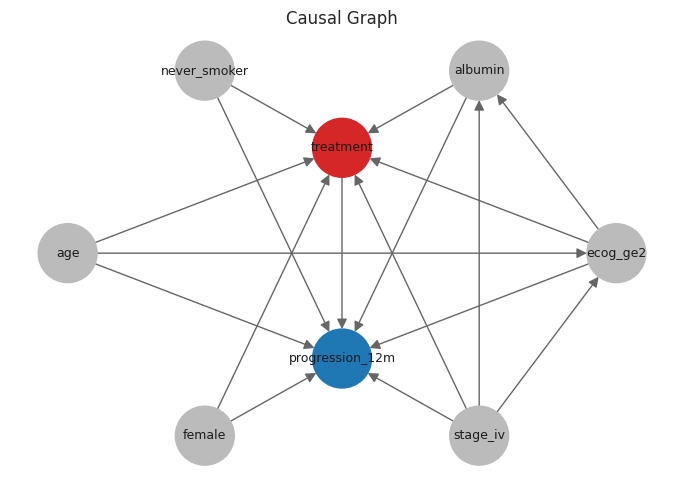

In [7]:
model, estimand = A.dowhy_model(pos)
import networkx as nx
g = A.causal_graph()
posn = nx.shell_layout(g, nlist=[[A.TREATMENT, A.OUTCOME], A.COVARIATES])
fig, ax = plt.subplots(figsize=(7, 5))
colors = ["#d62728" if n == A.TREATMENT else "#1f77b4" if n == A.OUTCOME else "#bbbbbb" for n in g.nodes]
nx.draw_networkx(g, posn, ax=ax, node_color=colors, node_size=1800, font_size=9, arrowsize=15, edge_color="#666")
ax.set_axis_off(); ax.set_title("Causal Graph")
plt.tight_layout()

## 3. Estimate the effects

A Bayesian model to test the causal graph we have seen for each site and across sites using a federated and pooled approach

In [12]:
SEED = 42
# Fit a hierarchical eyes on model
prior = A.fit_hierarchical(df, draws=500, prior_only=True, seed=SEED)
idata = A.fit_hierarchical(df, draws=1000, tune=1000, chains=4, seed=SEED)

# Fit a site level model
site_idatas = {s: A.fit_site_model(df[df["site"] == s], draws=1000, tune=1000, chains=4, seed=SEED) for s in SITES}
summaries = [A.site_summary(site_idatas[s], s) for s in SITES]

# Fit a federated model
meta = A.meta_analysis(summaries, seed=SEED)


Sampling: [beta, beta_egfr, mu_alpha, mu_tau, sigma_alpha, sigma_tau, tau_neg, y, z_alpha, z_tau]
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [mu_alpha, sigma_alpha, z_alpha, mu_tau, sigma_tau, z_tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 91 seconds.
There were 4 divergences after tuning. Increase `target_accept` or reparameterize.
Sampling: [y]
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 14 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [alpha, tau, tau_neg, beta, beta_egfr]
Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 14 seconds.
Initializing NUTS using jitter+adapt_diag...
Sequential s

## 4. Compare against the ground truth

Now we compare these approaches with the ground truth. The target is the sample-average true
risk difference $\frac{1}{n}\sum_i (p_{1i} - p_{0i})$ over the analysed EGFR+ patients.

In [13]:

def load_truth(sites: tuple[str, ...] = SITES) -> pd.DataFrame:
    frames = []
    for s in sites:
        df = spark.read.table(f"{s}.synthetic_ehr.ground_truth").toPandas()
        df["site"] = s
        frames.append(df)
    return pd.concat(frames, ignore_index=True)

In [14]:
truth = load_truth(SITES)
tv_pos = A.true_rd(truth, pos["patient_id"], egfr=1)
tv_neg = A.true_rd(truth, neg["patient_id"], egfr=0)
tv_site = {s: A.true_rd(truth, pos.loc[pos["site"] == s, "patient_id"]) for s in SITES}
print(f"true RD  EGFR+: {tv_pos:.4f} ")


true RD  EGFR+: -0.2874 


In [15]:
bayes_rows = [
    {"site": "pooled", "method": "pymc_hierarchical", **A.posterior_interval(idata, "ate_rd_egfr_pos"), "n": len(pos)},
    {"site": "pooled", "method": "federated_meta", **A.posterior_interval(meta, "mu"), "n": len(pos)},
]
for s in SITES:
    bayes_rows.append({"site": s, "method": "pymc_no_pooling", **A.posterior_interval(site_idatas[s], "ate_rd_egfr_pos"), "n": int((pos["site"] == s).sum())})
    hd = az.hdi(idata.posterior["ate_rd_site"].sel(site=s), hdi_prob=0.95)["ate_rd_site"].to_numpy()
    bayes_rows.append({"site": s, "method": "pymc_partial_pooling", "estimate": idata.posterior["ate_rd_site"].sel(site=s).mean().item(),
                       "ci_low": float(hd[0]), "ci_high": float(hd[1]), "n": int((pos["site"] == s).sum())})
all_est = pd.concat([pd.DataFrame(bayes_rows)], ignore_index=True)
scored = A.score_estimates(all_est, tv_pos)
scored["truth"] = scored["site"].map(tv_site).fillna(tv_pos)
scored["bias"] = scored["estimate"] - scored["truth"]
scored["covered"] = (scored["ci_low"] <= scored["truth"]) & (scored["truth"] <= scored["ci_high"])
included_methods = ["pymc_no_pooling","pymc_hierarchical","federated_meta"]
scored.loc[scored.method.isin(included_methods),:].sort_values(["site", "method"]).round(3)

def forest(tbl, truth=None, title="", ax=None):
    tbl = tbl.reset_index(drop=True)
    ax = ax or plt.gca()
    labels = [f"{r.site} - {r.method}" for r in tbl.itertuples()]
    y = np.arange(len(tbl))[::-1]
    palette={"westmids" : "#1f77b4","tvs" : "#2ca02c","hdrs" : "#ff7f0e","pooled": "#7f7f7f"}
    for yi, r in zip(y,tbl.itertuples()):
        c=palette.get(r.site,"#000")
        ax.plot([r.ci_low,r.ci_high],[yi,yi],color=c,lw=2)
        ax.plot(r.estimate,yi,"o",color=c)
    if truth is not None:
        ax.axvline(truth,color="k",ls="--",lw=1,label=f"truth = {truth:.3f}")
        ax.legend(loc="lower right")
    ax.axvline(0,color="k",lw =0.6)
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel("risk difference, 12-month progression")
    ax.set_title(title)
    return ax

site_dict = {'pooled': 'All sites','wessex': 'Wessex SDE','tvs' :'TVS SDE', 'westmids': 'Westmidlands SDE'}
method_dict = {'pymc_no_pooling': 'Individual estimate','pymc_hierarchical': 'Eyes on estimate',
               'federated_meta' : 'Eyes off estimate','pymc_partial_pooling' : 'partial pooling'}
scored.loc[:,'site'] = scored.loc[:,'site'].map(lambda x : site_dict[x])
scored.loc[:,'method'] = scored.loc[:,'method'].map(lambda x : method_dict[x])



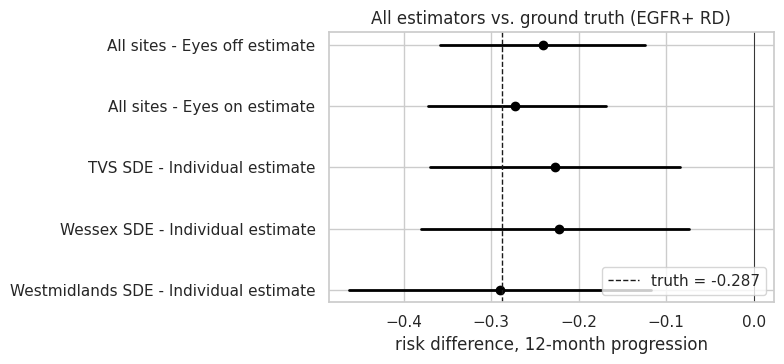

In [15]:
included_methods = ['Individual estimate','Eyes on estimate','Eyes off estimate']
## Plot the output
fig, ax = plt.subplots(figsize=(8, 0.35 * len(scored) + 1))
forest(scored.loc[scored.method.isin(included_methods),:].sort_values(["site", "method"]), truth=tv_pos, title="All estimators vs. ground truth (EGFR+ RD)", ax=ax)
plt.tight_layout()
